In [33]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import curve_fit
from scipy.stats import pearsonr

#load the csv file
df = pd.read_csv("dry straight hair data/Extension_Dry_200mmmin_S_sorted.csv")
print(df)

     Record  Strain (%)  Stress (MPa)
0         1         0.0           0.1
1         1         0.0           0.0
2         1         0.0          -0.1
3         1         0.0          -0.1
4         1         0.0          -0.1
..      ...         ...           ...
870      21         4.0          78.6
871      22         4.0           0.0
872      23         4.0          24.5
873      24         4.0          69.4
874      25         4.0          41.0

[875 rows x 3 columns]


In [34]:
#Convert columns to numbers
df["Strain (%)"] = pd.to_numeric(df["Strain (%)"], errors='coerce')
df["Stress (MPa)"] = pd.to_numeric(df["Stress (MPa)"], errors='coerce')
df = df.dropna(subset=["Strain (%)", "Stress (MPa)"])  # Drop rows with NaN values in these columns

#Sort by strain
df = df.sort_values("Strain (%)")

#Check the data
print(df.head())
print(df.info())

   Record  Strain (%)  Stress (MPa)
0       1         0.0           0.1
1       1         0.0           0.0
2       1         0.0          -0.1
3       1         0.0          -0.1
4       1         0.0          -0.1
<class 'pandas.core.frame.DataFrame'>
Index: 875 entries, 0 to 850
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Record        875 non-null    int64  
 1   Strain (%)    875 non-null    float64
 2   Stress (MPa)  875 non-null    float64
dtypes: float64(2), int64(1)
memory usage: 27.3 KB
None


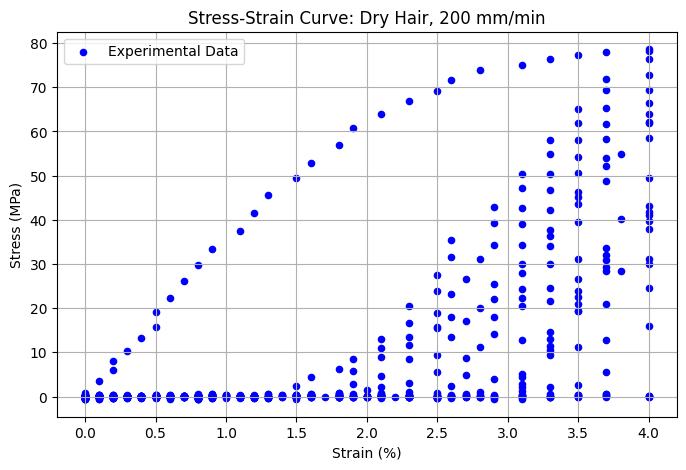

In [35]:
plt.figure(figsize=(8, 5)) #Raw stress-strain data
plt.scatter(df["Strain (%)"], df["Stress (MPa)"], s=20, label = "Experimental Data", color='blue')

plt.xlabel("Strain (%)")
plt.ylabel("Stress (MPa)")
plt.title("Stress-Strain Curve: Dry Hair, 200 mm/min")
plt.legend()
plt.grid(True)
plt.show()

In [36]:
mean_df = (df.groupby("Strain (%)")["Stress (MPa)"].agg(['mean', 'std']).reset_index())
print(mean_df)

    Strain (%)       mean        std
0          0.0   0.001282   0.192433
1          0.1   0.088636   0.557075
2          0.2   0.327907   1.538138
3          0.3   0.331250   1.843810
4          0.4   0.520000   2.646224
5          0.5   1.109375   4.310928
6          0.6   0.746667   4.093370
7          0.7   1.500000   6.140799
8          0.8   0.732500   4.721711
9          0.9   1.609091   7.127139
10         1.0   0.112500   0.216712
11         1.1   1.500000   7.501500
12         1.2   1.664000   8.321502
13         1.3   2.347368  10.452717
14         1.4   0.150000   0.207364
15         1.5   2.160000   9.853553
16         1.6   2.545833  10.740455
17         1.7   0.000000        NaN
18         1.8   2.684000  11.385249
19         1.9   5.607143  16.074177
20         2.0   0.136364   0.434218
21         2.1   4.433333  13.205521
22         2.2  -0.200000        NaN
23         2.3   5.700000  14.069411
24         2.5   7.424000  15.428877
25         2.6  13.060000  20.473425
2

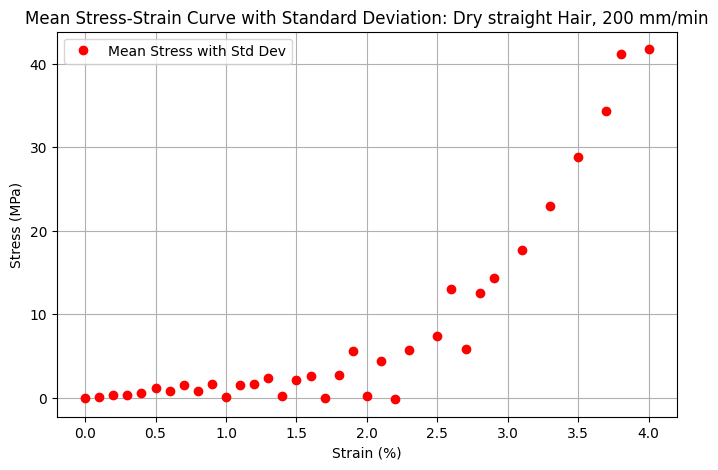

In [37]:
plt.figure(figsize=(8, 5)) 
plt.errorbar(mean_df["Strain (%)"], mean_df["mean"], fmt='o', label='Mean Stress with Std Dev', color='red', capsize=3)

plt.xlabel("Strain (%)")
plt.ylabel("Stress (MPa)")
plt.title("Mean Stress-Strain Curve with Standard Deviation: Dry straight Hair, 200 mm/min")
plt.legend()
plt.grid(True)
plt.show()

In [38]:
strain = mean_df["Strain (%)"].values
stress = mean_df["mean"].values

#Define the exponential model
def exponential(x, A, B):
    return A * (np.exp(B * x) - 1)

# 3. Set minimum number of points
# ==========================================

MIN_POINTS_TOE = 16
MIN_POINTS_ELASTIC = 8

# 4. Define possible breakpoints
# ==========================================

# Only search between these strain values
min_breakpoint = 0.01
max_breakpoint = 4.6

possible_breakpoints = np.linspace(min_breakpoint,max_breakpoint,100)

#5. Store results
# ==========================================

results = []


# 6. Test every possible breakpoint
# ==========================================
# loop through each possible breakpoint and fit the toe and elastic regions separately, then calculate the MSE for each fit.
for breakpoint in possible_breakpoints:

    # -----------------------------
    # Divide data
    # -----------------------------

    toe_mask = strain <= breakpoint
    elastic_mask = strain > breakpoint

    toe_strain = strain[toe_mask]
    toe_stress = stress[toe_mask]

    elastic_strain = strain[elastic_mask]
    elastic_stress = stress[elastic_mask]


    # -----------------------------
    # Minimum point requirement
    # -----------------------------

    if len(toe_strain) < MIN_POINTS_TOE:
        continue

    if len(elastic_strain) < MIN_POINTS_ELASTIC:
        continue


    # ==========================================
    # 7. Fit exponential to toe region
    # ==========================================

    try:

        popt_exp, _ = curve_fit(
            exponential,
            toe_strain,
            toe_stress,
            p0=[1, 1],
            maxfev=10000
        )

    except RuntimeError:

        continue


    A, B = popt_exp


    # Predicted toe stresses

    predicted_toe = exponential(
        toe_strain,
        A,
        B
    )


    # ==========================================
    # 8. Fit linear elastic region
    # ==========================================

    linear_coefficients = np.polyfit(
        elastic_strain,
        elastic_stress,
        1
    )

    E = linear_coefficients[0]
    C = linear_coefficients[1]


    # Predicted elastic stresses

    predicted_elastic = (
        E * elastic_strain + C
    )


    # ==========================================
    # 9. Calculate MSE
    # ==========================================

    toe_mse = np.mean(
        (toe_stress - predicted_toe) ** 2
    )

    elastic_mse = np.mean(
        (elastic_stress - predicted_elastic) ** 2
    )


    # ==========================================
    # 10. Combined MSE
    # ==========================================

    total_mse = toe_mse + elastic_mse #total MSE is the sum of the toe and elastic MSEs


    # ==========================================
    # 11. Store results
    # ==========================================

    results.append({
        "breakpoint": breakpoint,
        "toe_mse": toe_mse,
        "elastic_mse": elastic_mse,
        "total_mse": total_mse,
        "A": A,
        "B": B,
        "E": E,
        "C": C,
        "n_toe": len(toe_strain),
        "n_elastic": len(elastic_strain)
    })


#12. Convert results to DataFrame
# ==========================================

results_df = pd.DataFrame(results)


# ==========================================
# 13. Find best breakpoint
# ==========================================

best_index = results_df["total_mse"].idxmin()

best_result = results_df.loc[best_index]


print("\nBEST BREAKPOINT")
print("----------------------")

print(
    "Breakpoint strain:",
    best_result["breakpoint"]
)

print(
    "Toe MSE:",
    best_result["toe_mse"]
)

print(
    "Elastic MSE:",
    best_result["elastic_mse"]
)

print(
    "Total MSE:",
    best_result["total_mse"]
)

print(
    "Number of toe points:",
    int(best_result["n_toe"])
)

print(
    "Number of elastic points:",
    int(best_result["n_elastic"])
)

print("\nToe exponential parameters")

print(
    "A =",
    best_result["A"]
)

print(
    "B =",
    best_result["B"]
)

print("\nElastic linear parameters")

print(
    "E =",
    best_result["E"]
)

print(
    "C =",
    best_result["C"]
)


BEST BREAKPOINT
----------------------
Breakpoint strain: 2.606363636363636
Toe MSE: 2.5290109632207773
Elastic MSE: 2.844667820979816
Total MSE: 5.373678784200593
Number of toe points: 26
Number of elastic points: 9

Toe exponential parameters
A = 0.022075055920238246
B = 2.3964050557622234

Elastic linear parameters
E = 27.334993646759838
C = -66.14386785260477


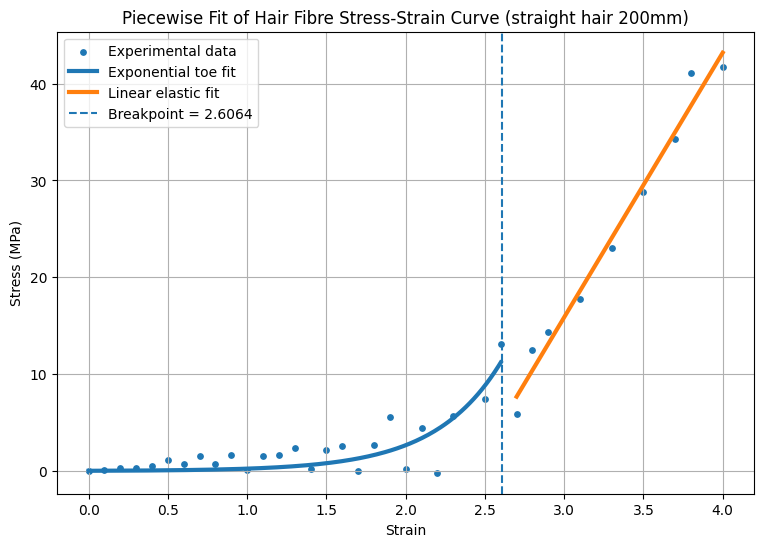

In [39]:
best_breakpoint = best_result["breakpoint"]

toe_mask = strain <= best_breakpoint
elastic_mask = strain > best_breakpoint

toe_strain = strain[toe_mask]
toe_stress = stress[toe_mask]

elastic_strain = strain[elastic_mask]
elastic_stress = stress[elastic_mask]


# Exponential fit

A = best_result["A"]
B = best_result["B"]

toe_x = np.linspace(
    toe_strain.min(),
    toe_strain.max(),
    200
)

toe_y = exponential(
    toe_x,
    A,
    B
)


# Linear fit

E = best_result["E"]
C = best_result["C"]

elastic_x = np.linspace(
    elastic_strain.min(),
    elastic_strain.max(),
    200
)

elastic_y = E * elastic_x + C


# Plot

plt.figure(figsize=(9, 6))

plt.scatter(
    strain,
    stress,
    s=15,
    label="Experimental data"
)

plt.plot(
    toe_x,
    toe_y,
    linewidth=3,
    label="Exponential toe fit"
)

plt.plot(
    elastic_x,
    elastic_y,
    linewidth=3,
    label="Linear elastic fit"
)

plt.axvline(
    best_breakpoint,
    linestyle="--",
    label=f"Breakpoint = {best_breakpoint:.4f}"
)

plt.xlabel("Strain")
plt.ylabel("Stress (MPa)")
plt.title("Piecewise Fit of Hair Fibre Stress-Strain Curve (straight hair 200mm)")

plt.legend()
plt.grid(True)

plt.show()

In [40]:
breakpoint = best_breakpoint

toe_mask = strain <= breakpoint
elastic_mask = strain > breakpoint

toe_strain = strain[toe_mask]
toe_stress = stress[toe_mask]

elastic_strain = strain[elastic_mask]
elastic_stress = stress[elastic_mask]

# 2. Calculate predicted stress
# ------------------------------------------

def exponential(x, A, B):
    return A * (np.exp(B * x) - 1)

predicted_toe = exponential(toe_strain, A, B)
predicted_elastic = E * elastic_strain + C

# 3. Toe-region length
# ------------------------------------------

toe_length = breakpoint - np.min(strain)

# ------------------------------------------
# 4. Stress at transition
# ------------------------------------------

stress_transition_toe = exponential(breakpoint, A, B)
stress_transition_elastic = E * breakpoint + C

# Difference between the two models at the breakpoint
transition_gap = stress_transition_elastic - stress_transition_toe

# 5. Effective toe-region stiffness
# ------------------------------------------

# Derivative of A*(exp(B*strain) - 1)
toe_stiffness_transition = A * B * np.exp(B * breakpoint)

# ------------------------------------------
# 6. Elastic modulus
# ------------------------------------------

elastic_modulus = E

# 7. Correlation and R-squared
# ------------------------------------------

def calculate_metrics(observed, predicted):
    residuals = observed - predicted

    sse = np.sum(residuals ** 2)
    mse = np.mean(residuals ** 2)
    rmse = np.sqrt(mse)

    sst = np.sum((observed - np.mean(observed)) ** 2)

    r_squared = 1 - sse / sst if sst > 0 else np.nan

    # Pearson correlation is undefined for constant arrays
    if (
        len(observed) >= 2
        and np.std(observed) > 0
        and np.std(predicted) > 0
    ):
        r = pearsonr(observed, predicted).statistic
    else:
        r = np.nan

    return {
        "r": r,
        "R_squared": r_squared,
        "SSE": sse,
        "MSE": mse,
        "RMSE": rmse,
        "residuals": residuals
    }

toe_metrics = calculate_metrics(toe_stress, predicted_toe)
elastic_metrics = calculate_metrics(elastic_stress, predicted_elastic)

all_stress = np.concatenate([toe_stress, elastic_stress])
all_predicted = np.concatenate([predicted_toe, predicted_elastic])

overall_metrics = calculate_metrics(all_stress, all_predicted)
regional_mse_sum = toe_metrics["MSE"] + elastic_metrics["MSE"]

# ------------------------------------------
# 8. Print results
# ------------------------------------------

print("\n===== HAIR FIBRE ANALYSIS =====")

print(f"Breakpoint strain: {breakpoint:.6f}")
print(f"Toe-region length: {toe_length:.6f}")

print("\nStress at transition:")
print(f"Exponential fit: {stress_transition_toe:.6f}")
print(f"Linear fit:      {stress_transition_elastic:.6f}")
print(f"Transition gap:  {transition_gap:.6f}")

print("\nToe-region stiffness at transition:")
print(f"{toe_stiffness_transition:.6f} stress units per strain unit")

print("\nElastic modulus:")
print(f"{elastic_modulus:.6f} stress units per strain unit")

print(f"\nRegional MSE sum (toe + elastic): {regional_mse_sum:.6f}")

for name, metrics in [
    ("TOE REGION", toe_metrics),
    ("ELASTIC REGION", elastic_metrics),
    ("OVERALL", overall_metrics)
]:
    print(f"\n{name}")
    print(f"Pearson r: {metrics['r']:.5f}")
    print(f"R-squared: {metrics['R_squared']:.5f}")
    print(f"SSE:       {metrics['SSE']:.6f}")
    mse_label = "Overall pooled MSE" if name == "OVERALL" else "MSE"
    print(f"{mse_label}: {metrics['MSE']:.6f}")
    print(f"RMSE:      {metrics['RMSE']:.6f}")


===== HAIR FIBRE ANALYSIS =====
Breakpoint strain: 2.606364
Toe-region length: 2.606364

Stress at transition:
Exponential fit: 11.366333
Linear fit:      5.101066
Transition gap:  -6.265267

Toe-region stiffness at transition:
27.291239 stress units per strain unit

Elastic modulus:
27.334994 stress units per strain unit

Regional MSE sum (toe + elastic): 5.373679

TOE REGION
Pearson r: 0.85827
R-squared: 0.70648
SSE:       65.754285
MSE: 2.529011
RMSE:      1.590286

ELASTIC REGION
Pearson r: 0.99035
R-squared: 0.98078
SSE:       25.602010
MSE: 2.844668
RMSE:      1.686614

OVERALL
Pearson r: 0.99107
R-squared: 0.98117
SSE:       91.356295
Overall pooled MSE: 2.610180
RMSE:      1.615605


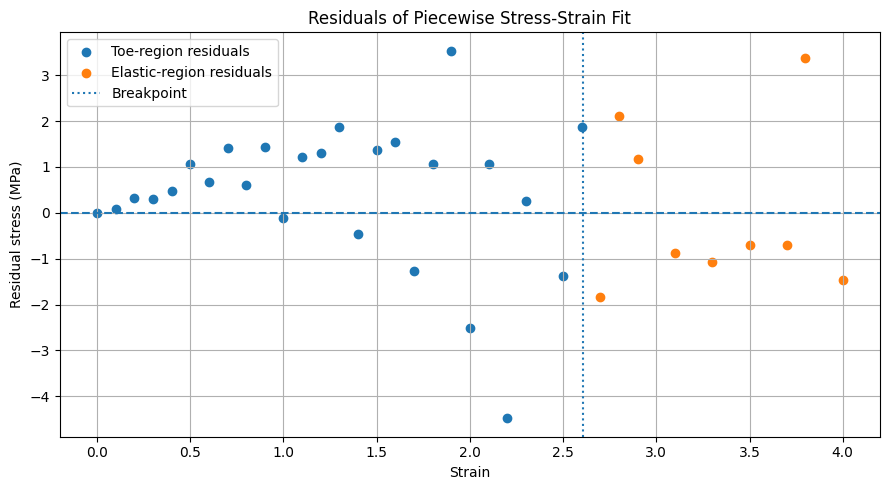

In [41]:
toe_residuals = toe_stress - predicted_toe
elastic_residuals = elastic_stress - predicted_elastic

plt.figure(figsize=(9, 5))

plt.scatter(
    toe_strain, toe_residuals,
    label="Toe-region residuals"
)

plt.scatter(
    elastic_strain, elastic_residuals,
    label="Elastic-region residuals"
)

plt.axhline(0, linestyle="--")

plt.axvline(
    breakpoint,
    linestyle=":",
    label="Breakpoint"
)

plt.xlabel("Strain")
plt.ylabel("Residual stress (MPa)")
plt.title("Residuals of Piecewise Stress-Strain Fit")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()